# Task 4 — Channel effectiveness

**Status:** all supplied-data analysis is executed. Human observations are deliberately unfilled. Run the interactive collection cell, use a real reader, then rerun the analysis cells below it. Blank responses are not evidence. No simulated results are used.

Charts use the object-oriented Matplotlib API. Experimental stimuli intentionally retain the supplied colours and omit titles where the brief requires this; they are displays for testing perception, not final explanatory charts.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle, Wedge
from IPython.display import display
DATA = Path('data'); RESULTS = Path('results'); FIGURES = Path('figures')
RESULTS.mkdir(exist_ok=True); FIGURES.mkdir(exist_ok=True)
SEED = 42
GREY = '#b9bdc3'; ACCENT = '#bd3f58'
plt.rcParams.update({'figure.dpi': 110, 'axes.titlesize': 12, 'axes.labelsize': 10})
def clean(ax):
    for side in ('top','right'): ax.spines[side].set_visible(False)
def save(fig, name):
    fig.savefig(FIGURES / name, dpi=300, bbox_inches='tight')


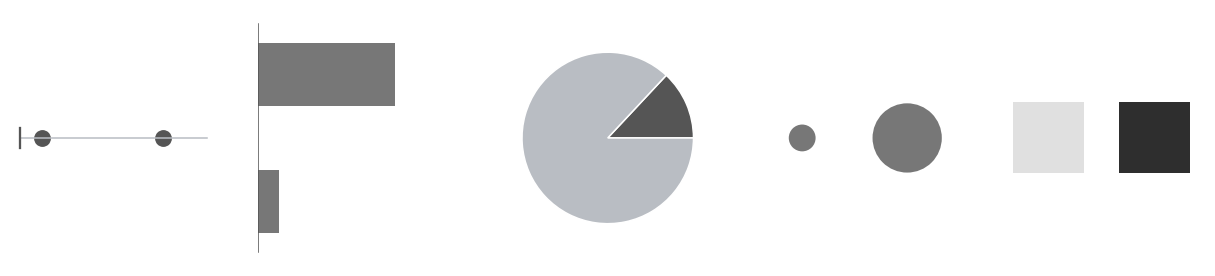

In [2]:
trials=pd.read_csv(DATA/'channel_trials.csv')
def position_chart(row,ax):
    # Explicit zero reference is essential for judging a ratio from positions.
    ax.plot([0,100],[0,0],color=GREY,lw=1)
    ax.scatter([row.value_small,row.value_large],[0,0],s=100,color='#555555')
    ax.plot([0,0],[-.08,.08],color='#555555');ax.set_xlim(-5,105);ax.set_ylim(-1,1)
def length_chart(row,ax):
    ax.barh([0,1],[row.value_small,row.value_large],color='#777777',height=.5)
    ax.plot([0,0],[-.4,1.4],color='#555555',lw=1);ax.set_xlim(0,105);ax.set_ylim(-.5,1.5)
def angle_chart(row,ax):
    # Two sectors of a single pie; angle_small / angle_large equals the true ratio.
    theta=360*row.value_small/(row.value_small+row.value_large)
    ax.add_patch(Wedge((0,0),1,0,theta,facecolor='#555555',edgecolor='white'))
    ax.add_patch(Wedge((0,0),1,theta,360,facecolor=GREY,edgecolor='white'))
    ax.set_xlim(-1.2,1.2);ax.set_ylim(-1.2,1.2);ax.set_aspect('equal')
def area_chart(row,ax):
    for x,value in zip([0,2.5],[row.value_small,row.value_large]):
        ax.add_patch(Circle((x,0),np.sqrt(value/100),facecolor='#777777'))
    ax.set_xlim(-1.2,3.7);ax.set_ylim(-1.3,1.3);ax.set_aspect('equal')
def colour_chart(row,ax):
    # Sequential grayscale: darkness = value/100; no rainbow.
    for x,value in zip([0,1.5],[row.value_small,row.value_large]):
        ax.add_patch(Rectangle((x,0),1,1,facecolor=str(1-value/100)))
    ax.set_xlim(-.2,2.7);ax.set_ylim(-.2,1.2);ax.set_aspect('equal')
renderers={'position':position_chart,'length':length_chart,'angle':angle_chart,'area':area_chart,'colour':colour_chart}
def draw_channel(row,ax):
    renderers[row.channel](row,ax);ax.set_axis_off()
fig,axes=plt.subplots(1,5,figsize=(14,3))
for ax,channel in zip(axes,renderers):
    draw_channel(trials[trials.channel.eq(channel)].iloc[0],ax)
save(fig,'task4_channel_examples.png');plt.show()


**Five encodings, left to right:** position, length, angle, area, lightness. No numbers or labels appear in stimulus plots. A visible zero-origin mark makes position ratios meaningful; length shares a zero baseline. Angle uses two complementary sectors whose angles have the same ratio as the two values. Area uses radius = square root of value / 100, so area is proportional to value. Lightness uses a monotone grey ramp; display gamma means it is an approximate lightness channel, not a calibrated psychophysical measure. Proximity pairs the two marks; enclosure defines each sector or shape. Hue does not identify a nominal variable. Before collecting, tell the reader that darkness, rather than brightness, represents greater value for the colour trials. Do not show true ratios.

In [3]:
import ipywidgets as widgets
path=RESULTS/'channel_results.csv'
if not path.exists():trials.assign(participant='').to_csv(path,index=False)
schedule=trials.sample(frac=1,random_state=SEED).reset_index(drop=True)
reader=widgets.Text(description='Reader:');estimate=widgets.FloatText(value=50,description='Percent:')
start=widgets.Button(description='Show next');submit=widgets.Button(description='Record estimate');out=widgets.Output();status=widgets.HTML();state={'i':0,'row':None}
def next_channel(_):
    if not reader.value.strip():status.value='Enter a real reader.';return
    if state['row'] is not None:return
    if state['i']>=len(schedule):status.value='All 30 trials recorded. Rerun analysis.';return
    state['row']=schedule.iloc[state['i']]
    with out:
        out.clear_output(wait=True);fig,ax=plt.subplots(figsize=(5,3));draw_channel(state['row'],ax);display(fig);plt.close(fig)
    status.value='The smaller value is what percentage of the larger?'
def record_channel(_):
    if state['row'] is None:return
    if not 0<=estimate.value<=100:status.value='Enter a percentage from 0 to 100.';return
    row=state['row'];d=pd.read_csv(path);idx=d.index[d.trial.eq(row.trial)][0]
    d.loc[idx,['reader_estimate','absolute_error','participant']]=[estimate.value,abs(estimate.value/100-row.true_ratio),reader.value.strip()]
    d.to_csv(path,index=False);state['i']+=1;state['row']=None;status.value='Recorded. Show next when ready.'
start.on_click(next_channel);submit.on_click(record_channel)
display(widgets.VBox([reader,status,start,out,estimate,submit]))


In [4]:
results=pd.read_csv(path)
results['absolute_error']=(results.reader_estimate/100-results.true_ratio).abs()
results.to_csv(path,index=False)
observed=results.dropna(subset=['reader_estimate'])
if observed.empty:print('PENDING: no real-reader estimates. No channel ranking can be computed.')
else:
    ranking=observed.groupby('channel').agg(mean_absolute_error=('absolute_error','mean'),n=('absolute_error','size')).sort_values('mean_absolute_error')
    display(ranking)
    fig,ax=plt.subplots(figsize=(8,5));ax.barh(ranking.index,100*ranking.mean_absolute_error,color=[ACCENT]+[GREY]*(len(ranking)-1))
    ax.invert_yaxis();ax.set_xlim(left=0);ax.set_xlabel('Mean absolute error (percentage points)')
    ax.set_title('Observed channel accuracy for one reader',loc='left')
    for i,error in enumerate(100*ranking.mean_absolute_error):ax.text(error+.15,i,f'{error:.1f}',va='center')
    clean(ax);save(fig,'task4_channel_ranking.png');plt.show()
    expected=['position','length','angle','area','colour']
    print('Observed best to worst:',list(ranking.index));print('Reference order (volume untested):',expected)
    print('Observed trials:',len(observed),'of 30. Partial rankings are provisional.')


PENDING: no real-reader estimates. No channel ranking can be computed.


**Ranking chart:** position and zero-baseline length communicate error, sorted for accurate comparison. One accent marks the lowest observed mean; text and rank also identify it. Proximity groups each direct label with its bar. Error is an absolute ratio error, multiplied by 100 for percentage points, not relative percentage error. After collection, state each agreement and reversal; there are no observations to compare yet. With six ratios per channel and one person, this can describe that reader’s responses and demonstrate the method. It cannot establish population accuracy, stable channel ordering, statistical significance, or generalise across displays. Volume is not tested. The broader research ranking remains a useful default because it rests on a much broader evidence base than this exercise; position/length here may be especially similar because bars are read partly by endpoint position.

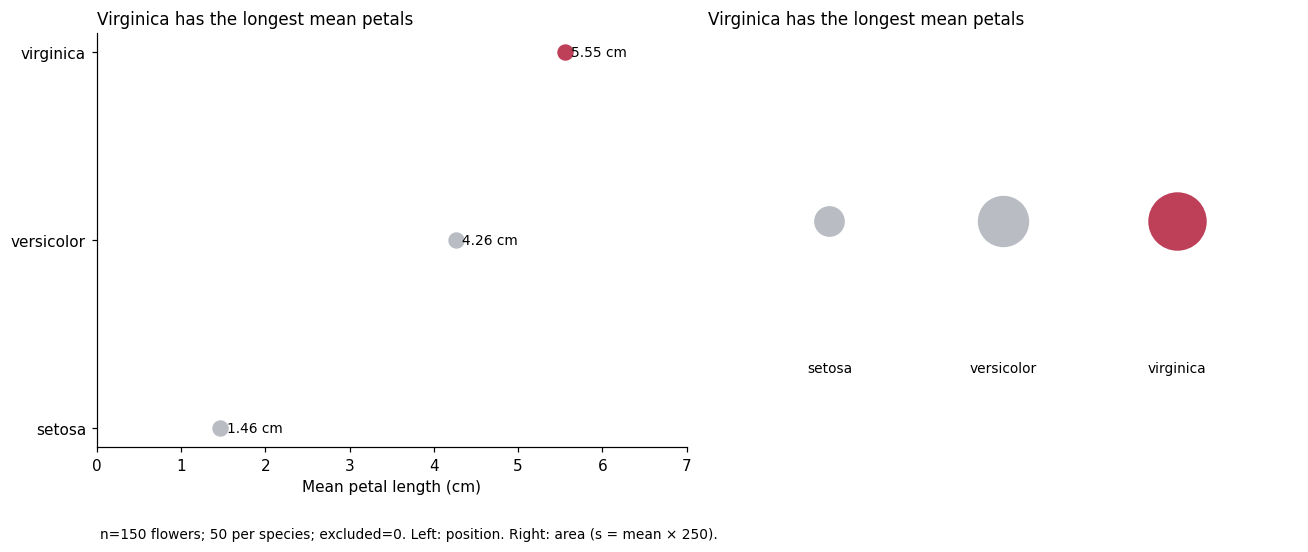

species
setosa        1.462
versicolor    4.260
virginica     5.552
Name: petal_length, dtype: float64

In [5]:
iris=pd.read_csv(DATA/'iris.csv'); means=iris.groupby('species').petal_length.mean().sort_values()
fig,axes=plt.subplots(1,2,figsize=(12,5));high,low=axes
for i,(species,value) in enumerate(means.items()):
    high.scatter(value,i,s=95,color=ACCENT if species=='virginica' else GREY)
    high.text(value+.08,i,f'{value:.2f} cm',va='center',fontsize=9)
    low.scatter(i,0,s=value*250,color=ACCENT if species=='virginica' else GREY)
    low.text(i,-.8,species,ha='center',fontsize=9)
high.set_yticks(range(3),means.index);high.set_xlim(0,7);high.set_xlabel('Mean petal length (cm)');clean(high)
low.set_xlim(-.7,2.7);low.set_ylim(-1.2,1);low.set_axis_off()
for ax in axes:ax.set_title('Virginica has the longest mean petals',loc='left',fontsize=11)
fig.text(.08,.01,'n=150 flowers; 50 per species; excluded=0. Left: position. Right: area (s = mean × 250).',fontsize=9)
fig.tight_layout(rect=[0,.06,1,1]);save(fig,'task4_iris_channels.png');plt.show();display(means)


**Same finding, same summaries:** each panel shows three species means from all 150 flowers, with exactly one highlighted species. Left uses position on a common quantitative scale, supported by direct values; right uses circle area (Matplotlib `s` proportional to the value, **not its square**). Proximity ties species labels to marks. Virginica is identified by its position/label and larger circle as well as colour. Publish the position chart: readers can compare differences and ratios against a shared scale; the area panel makes quantitative decoding harder. Both aggregate and hide individual variation. The right panel is a lower-ranking demonstration rather than the chosen final design.